# mlfilter-scale: FMQA 閉ループの確認実験(L=7、予算 100、15 Seed)

XY-FMQAOA(ペナルティ不要)と、ペナルティ係数の調整に失敗した FMQA(SA、α=0.3・α=100)、調整済み(α=1)、ランダムの比較。条件と仮説は `experiments/mlfilter-scale/bbo_confirm.json` に実行前に固定した。入力ファイルの SHA-256 は `analysis_config.json`。

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import plot, matplotlib
from IPython.display import Image, display
print('python', sys.executable, '| matplotlib', matplotlib.__version__)
plot.build_csv()

python /home/jovyan/FMA/.venv/bin/python | matplotlib 3.11.1


CSV written: best_rank_curves.csv, best_rank_summary.csv, final_per_seed.csv


## 図: 最良解の真の順位と最適解への到達(`bbo_l7_confirm`)

- (a) 横軸: 評価回数(最初の 40 回は全条件共通の初期点)。縦軸: それまでに評価した中で最良の解の真の順位(全 16,384 候補中、1 = 最適解、対数軸)。線は 15 Seed の中央値、帯は IQR(XY、α=1、α=100 のみ)。小さいほど良い
- (b) 縦軸: その評価回数までに最適解を見つけた Seed の割合。大きいほど良い
- 線: 青の実線 = XY-FMQAOA、黒の破線 = SA α=1(調整済み)、橙の実線 = SA α=100(大きすぎ)、緑の一点鎖線 = SA α=0.3(小さすぎ)、灰色の破線 = ランダム提案 + FM 選択、灰色の点線 = ランダム探索
- 見るところ: XY は α=0.3・α=100 より早く・多く最適解に届く(100 評価で 13/15 対 0/15・2/15)。α=1 とは中央値の軌跡がほぼ重なる
- 注意: α=0.3 は新しい実行可能な候補が出ないサイクルが多く、60 サイクルで 50〜65 評価しか使わなかった。その後は最良値をそのまま延ばして描いた(評価予算を使い切っていない)。α=1 も 4 Seed で 97〜99 評価
- 限界: 1 つの問題(L=7)・予算 100。XY は理想シミュレーションで、1 Seed 約 40 分(SA は数秒)

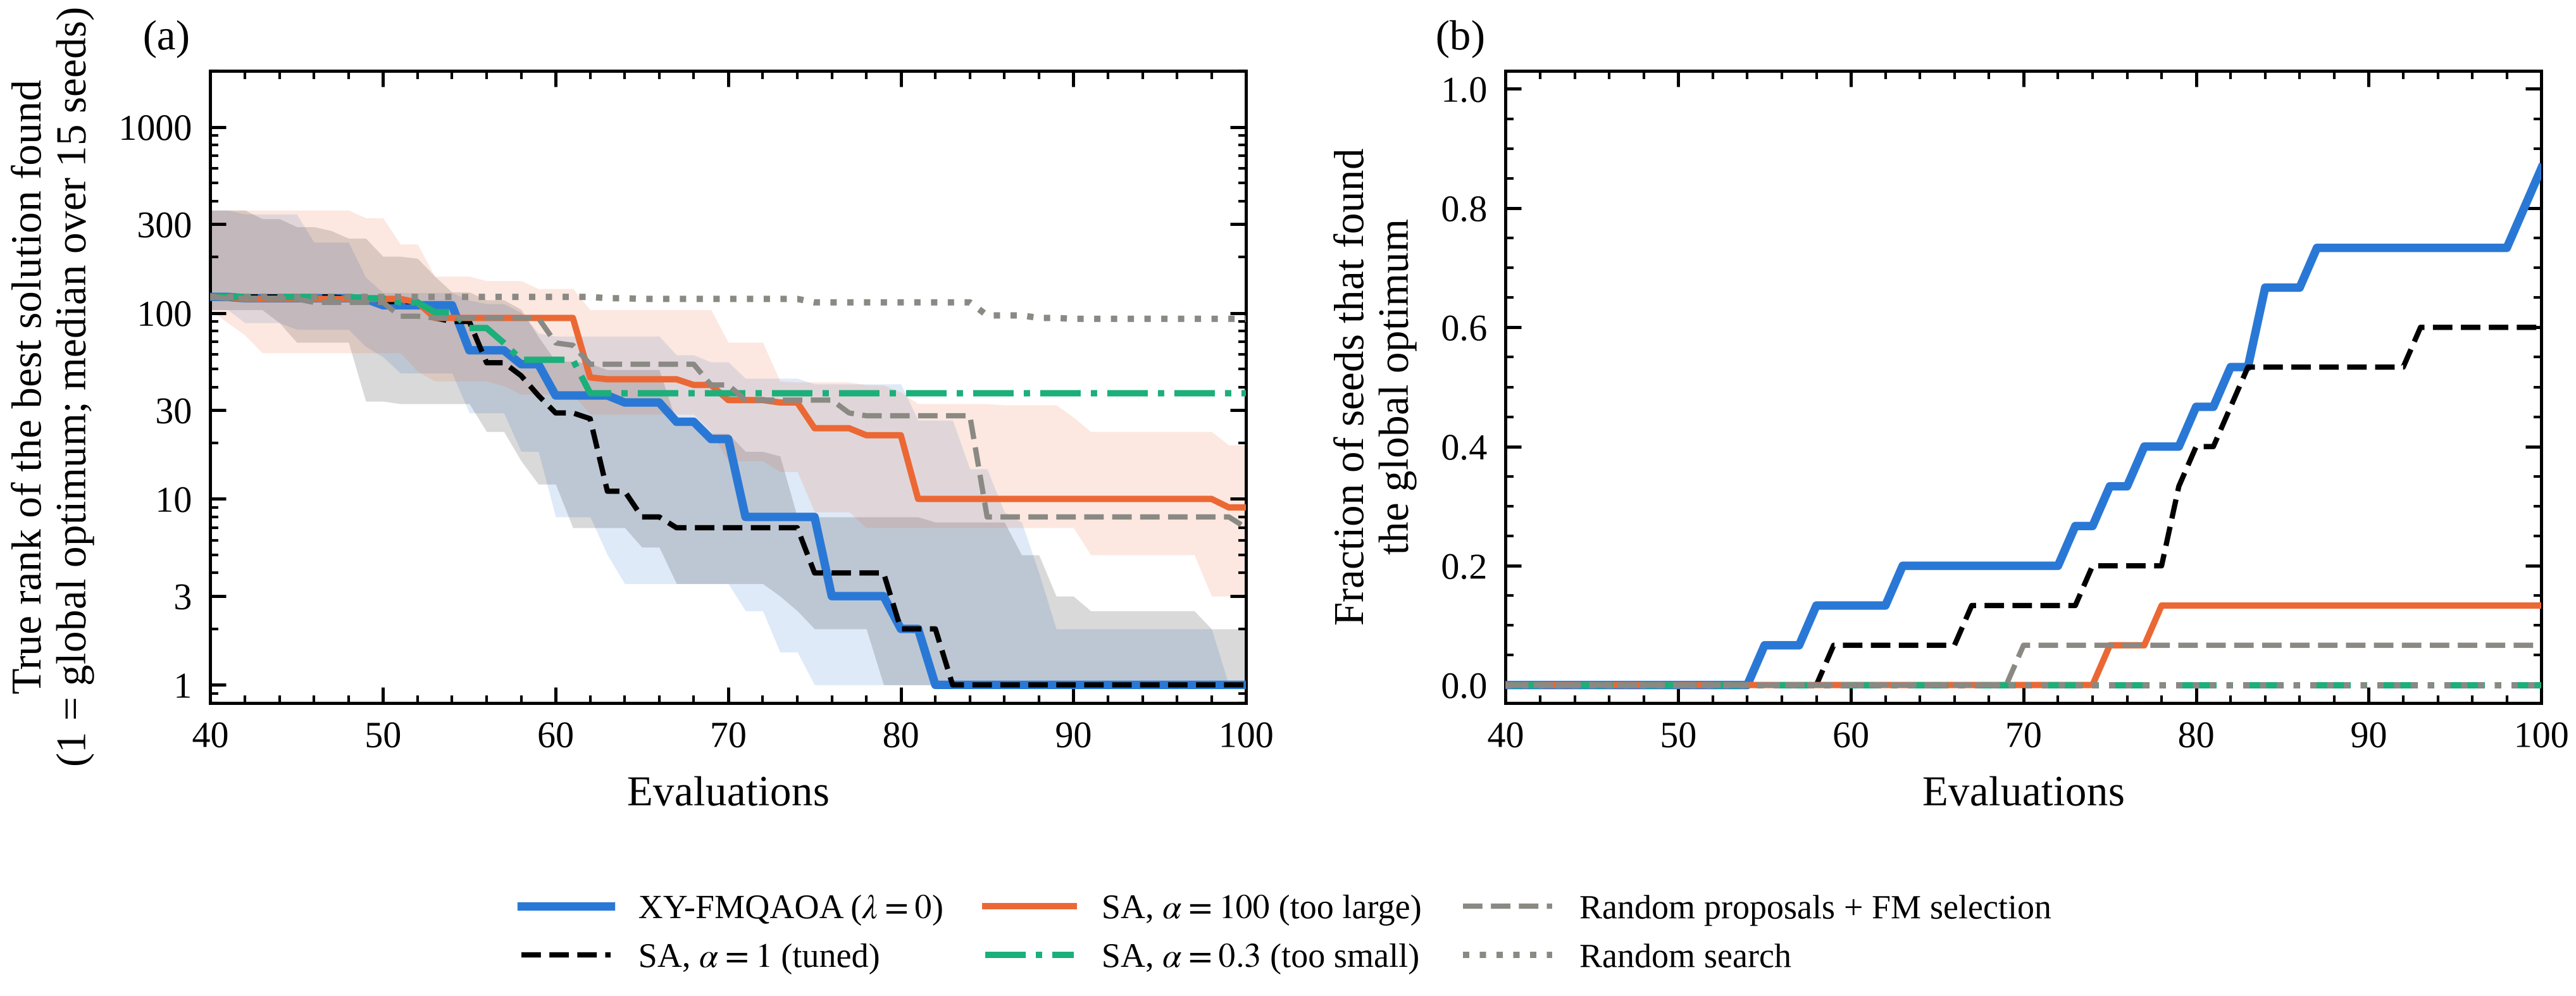

In [2]:
plot.fig_bbo(); display(Image('png/bbo_l7_confirm.png'))

## 事前に固定した検定の結果

In [3]:
s = json.loads((plot.PROJECT/plot.CONFIG['input']['run_dir']/'raw/summary.json').read_text())
for c, v in s['summary'].items(): print(f"{c:10s} optimum {v['successes']}/{v['n']}  median rank {v['best_rank'][0]:.0f} [{v['best_rank'][1]:.0f}, {v['best_rank'][2]:.0f}]")
print(json.dumps(s['tests'], indent=1))

XY-FMQAOA  optimum 13/15  median rank 1 [1, 1]
alpha0.3   optimum 0/15  median rank 37 [10, 148]
alpha100   optimum 2/15  median rank 9 [3, 20]
alpha1     optimum 9/15  median rank 1 [1, 2]
RandomFM   optimum 1/15  median rank 7 [4, 27]
Random     optimum 0/15  median rank 93 [68, 126]
{
 "H1": {
  "n_pairs": 15,
  "xy_better": 15,
  "ties": 0,
  "xy_worse": 0,
  "median_difference": -36.0,
  "p_raw": 0.00032419262673079855,
  "p_bonferroni": 0.0006483852534615971,
  "supported": true
 },
 "H2": {
  "n_pairs": 15,
  "xy_better": 13,
  "ties": 1,
  "xy_worse": 1,
  "median_difference": -8.0,
  "p_raw": 0.0010197617827099135,
  "p_bonferroni": 0.002039523565419827,
  "supported": true
 },
 "secondary_vs_alpha1": {
  "n_pairs": 15,
  "xy_better": 5,
  "ties": 8,
  "xy_worse": 2,
  "median_difference": 0.0,
  "p_raw": 0.1731945874792824
 },
 "conclusion_supported": true
}
